# Local handwriting: baseline versus preprocessing
Place one English handwritten text line per image in data/local/images/. Edit templates/local_images.csv: paths are relative to that CSV. Replace the example filename, add rows, and leave ground_truth blank until transcribed. Quote CSV fields containing commas. Only manifest-listed images are loaded.
Use validation for development; reserve test images (preferably distinct writers/pages) for final evaluation. Missing labels are unscored, never treated as empty reference text. Metrics collapse whitespace and retain case/punctuation. Results describe this collection only.
EXIF orientation, white transparency compositing and RGB decoding apply equally before every pipeline; source files remain untouched. Denoising and deskewing are evaluated individually. Full-page segmentation is outside this notebook.

In [4]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import hashlib
import json
import platform
from datetime import datetime, timezone
from importlib.metadata import version
import matplotlib.pyplot as plt
import pandas as pd
from src.load_dataset.local import load_local_samples
from src.models import TrOCRRecognizer
from src.preprocessing import PreprocessingPipeline, NonLocalMeans, Deskew
from src.evaluation import compare_recognition

In [5]:
MANIFEST = ROOT / "templates" / "local_images.csv"
SPLIT = "validation"
CHECKPOINT = "microsoft/trocr-base-handwritten"
MODEL_REVISION = "eaacaf452b06415df8f10bb6fad3a4c11e609406"
DEVICE = "cpu"
GENERATION = {"max_new_tokens": 128, "num_beams": 1, "do_sample": False}
pipelines = {
    "baseline": PreprocessingPipeline(),
    "denoising_h3": PreprocessingPipeline((NonLocalMeans(h=3.0, h_color=3.0),)),
    "deskew": PreprocessingPipeline((Deskew(),)),
}

In [7]:
# Validate inputs before downloading/loading the model.
manifest_text = MANIFEST.read_text(encoding="utf-8-sig")
manifest_sha256 = hashlib.sha256(MANIFEST.read_bytes()).hexdigest()
samples = load_local_samples(MANIFEST, split=SPLIT)
print({"selected": len(samples), "labeled": sum(s["ground_truth"] is not None for s in samples), "split": SPLIT})
display(pd.DataFrame([{k: v for k, v in s.items() if k != "image"} for s in samples]))

{'selected': 10, 'labeled': 10, 'split': 'validation'}


,id,ground_truth,image_path,sha256,condition,split,original_mode,original_size
0,img01,The sky is a deep blue color today,../data/local/images/img01.jpeg,43d7f5103fef7b7858e7a2f54c4a76038eb3a4da8183ce...,,validation,RGB,"(1453, 178)"
1,img02,Please bring my notebook tomorrow,../data/local/images/img02.jpg,a4e72fb32d2a62ead24a330521fb3f59174efa313f4c79...,,validation,RGB,"(1367, 177)"
2,img03,She wrote a letter to her friend,../data/local/images/img03.jpeg,f6af65bb5a5721922b4441d75019f5626167aa78744a3f...,,validation,RGB,"(1425, 179)"
3,img04,The train leaves at past helf time,../data/local/images/img04.jpeg,efe4b4e9bbf6440eb1a0cacb0bf89511bef25baaa5b631...,,validation,RGB,"(1351, 174)"
4,img05,I bought three apples and two pears,../data/local/images/img05.jpeg,61f7075427463acffd3fe31840aa2ca69f646b81e297ba...,,validation,RGB,"(1130, 178)"
5,img06,I was about to leave the house when I realized,../data/local/images/img06.jpeg,2b856d9617cd3d2eefd8eee9cc96e7a21088aa78d9e069...,,validation,RGB,"(1813, 145)"
6,img07,"As far as I know, they haven't made a final de...",../data/local/images/img07.jpeg,0375e45db81bcb140f7d5f9d2b7039af2ceab2c9b624d8...,,validation,RGB,"(1969, 190)"
7,img08,"I've been meaning to get around to it, but som...",../data/local/images/img08.jpeg,871218d969216b609cd2096dc8e5e41e5d68714362d6a0...,,validation,RGB,"(1880, 180)"
8,img09,It slipped my mind,../data/local/images/img09.jpeg,82f2e40339a7b6fe53152d967dcd0db08eeb6ed8137abc...,,validation,RGB,"(740, 162)"
9,img10,I'm running a bit late,../data/local/images/img10.jpeg,cef74801842414b2eb8c6545d7804b0dc9fccc0b4532c2...,,validation,RGB,"(948, 169)"


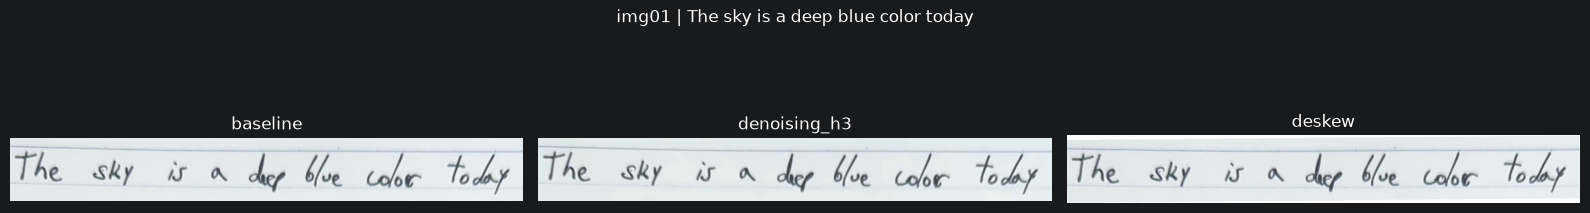

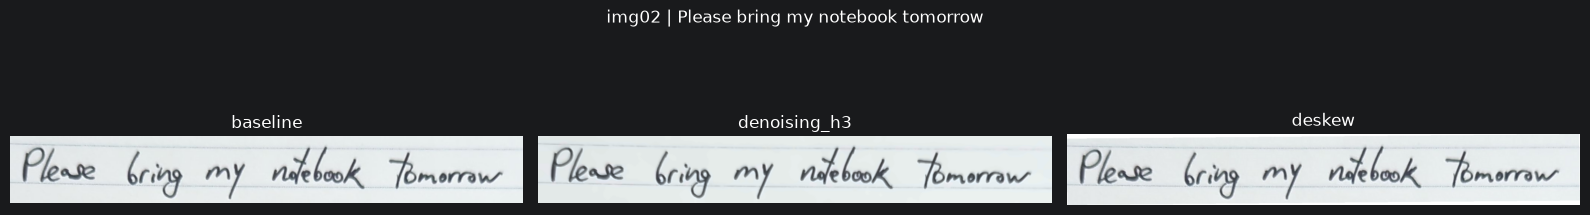

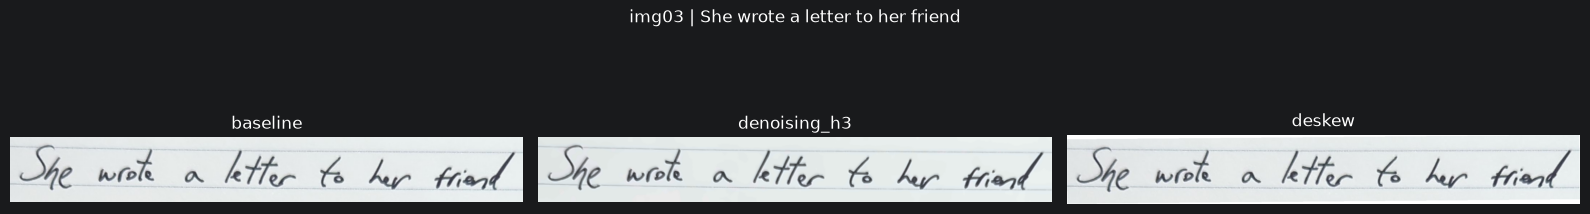

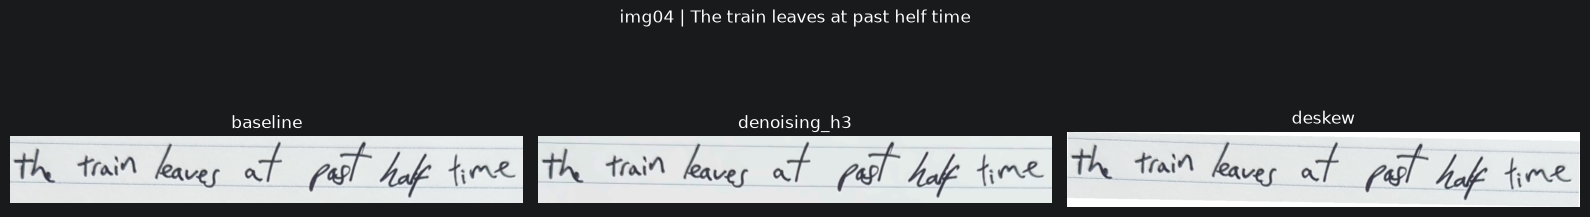

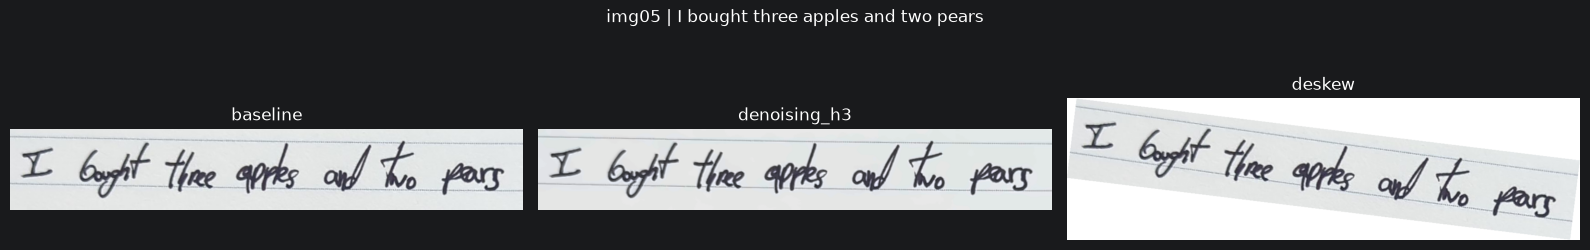

In [9]:
# Preview a few images through each pipeline.
for sample in samples[:5]:
    fig, axes = plt.subplots(1, len(pipelines), figsize=(16, 3), squeeze=False)
    for ax, (name, pipeline) in zip(axes[0], pipelines.items()):
        ax.imshow(pipeline(sample["image"]))
        ax.set_title(name)
        ax.axis("off")
    fig.suptitle(sample["id"] + " | " + (sample["ground_truth"] or "(unlabeled)"))
    plt.tight_layout()
    plt.show()

In [10]:
model = TrOCRRecognizer(CHECKPOINT, revision=MODEL_REVISION, device=DEVICE,
                        generation_kwargs=GENERATION)
rows, summaries = compare_recognition(samples, model, pipelines)
predictions = pd.DataFrame(rows)
summary = pd.DataFrame(summaries).set_index("configuration")
for metric in ("cer", "wer"):
    summary[metric] = pd.to_numeric(summary[metric], errors="coerce")
    summary[metric + "_change_from_baseline"] = summary[metric] - summary.loc["baseline", metric]
display(summary)
display(predictions[["configuration", "sample_id", "ground_truth", "prediction", "cer", "wer"]])
print("CER/WER are fractions; NaN means unavailable. Negative changes indicate improvement.")

W1104 13:04:36.895000 87546 .venv/lib/python3.13/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/478 [00:00<?, ?it/s]

[transformers] VisionEncoderDecoderModel LOAD REPORT from: microsoft/trocr-base-handwritten
Key                         | Status  | 
----------------------------+---------+-
encoder.pooler.dense.weight | MISSING | 
encoder.pooler.dense.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


baseline: 1/10
baseline: 2/10
baseline: 3/10
baseline: 4/10
baseline: 5/10
baseline: 6/10
baseline: 7/10
baseline: 8/10
baseline: 9/10
baseline: 10/10
denoising_h3: 1/10
denoising_h3: 2/10
denoising_h3: 3/10
denoising_h3: 4/10
denoising_h3: 5/10
denoising_h3: 6/10
denoising_h3: 7/10
denoising_h3: 8/10
denoising_h3: 9/10
denoising_h3: 10/10
deskew: 1/10
deskew: 2/10
deskew: 3/10
deskew: 4/10
deskew: 5/10
deskew: 6/10
deskew: 7/10
deskew: 8/10
deskew: 9/10
deskew: 10/10


,sample_count,scored_sample_count,cer,wer,inference_seconds,cer_change_from_baseline,wer_change_from_baseline
configuration,,,,,,,
baseline,10,10,0.030303,0.160000,9.236404,0.000000,0.000000
denoising_h3,10,10,0.030303,0.160000,6.943791,0.000000,0.000000
deskew,10,10,0.038567,0.186667,6.986256,0.008264,0.026667


,configuration,sample_id,ground_truth,prediction,cer,wer
0,baseline,img01,The sky is a deep blue color today,The sky is a deep blue colour today,0.029412,0.125000
1,baseline,img02,Please bring my notebook tomorrow,Please bring my notebook tomorrow .,0.060606,0.200000
2,baseline,img03,She wrote a letter to her friend,She wrote a letter to her friend,0.000000,0.000000
3,baseline,img04,The train leaves at past helf time,the train leaves at past half time,0.058824,0.285714
4,baseline,img05,I bought three apples and two pears,I bought three apples and two years .,0.085714,0.285714
5,baseline,img06,I was about to leave the house when I realized,I was about to leave the house when I realized,0.000000,0.000000
6,baseline,img07,"As far as I know, they haven't made a final de...","As far as I know , they haven't made a final d...",0.035088,0.333333
7,baseline,img08,"I've been meaning to get around to it, but som...","I've been meaning to get around to it , but so...",0.019231,0.200000
8,baseline,img09,It slipped my mind,It slipped my mind,0.000000,0.000000
9,baseline,img10,I'm running a bit late,I'm running a bit late,0.000000,0.000000


CER/WER are fractions; NaN means unavailable. Negative changes indicate improvement.


In [11]:
run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
output = ROOT / "results" / ("local_trocr_" + run_id)
metadata = {
    "experiment_id": run_id, "dataset": "local_images", "split": SPLIT,
    "manifest": str(MANIFEST.relative_to(ROOT)) if MANIFEST.is_relative_to(ROOT) else str(MANIFEST),
    "manifest_sha256": manifest_sha256, "manifest_contents": manifest_text,
    "samples": [{k: v for k, v in s.items() if k != "image"} for s in samples],
    "input_policy": "EXIF transpose; alpha composite on white; RGB; source files unchanged",
    "model": model.to_config(),
    "pipelines": {name: pipe.to_config() for name, pipe in pipelines.items()},
    "normalization": "collapse whitespace; strip edges; retain case and punctuation",
    "scoring": "only nonblank labeled samples; corpus edit totals / reference totals",
    "python": platform.python_version(),
    "versions": {name: version(name) for name in ["torch", "transformers", "Pillow",
        "opencv-python-headless", "numpy", "jiwer", "pandas", "huggingface-hub", "matplotlib"]},
    "timing": "wall seconds; excludes model loading; preprocessing and inference recorded separately",
}
output.mkdir(parents=True, exist_ok=False)
predictions.to_csv(output / "predictions.csv", index=False)
summary.to_csv(output / "summary.csv")
(output / "metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print("Saved:", output)

Saved: /Users/vmendoza/Documents/Lakehead/RM/COMP-5112-Research-Methodology/results/local_trocr_20261104T180604254236Z
